# Exploration of h5 file and basic SENSE (Sensitivity Encoding)



In [10]:
import numpy as np
import h5py
from matplotlib import pyplot as plt
import scipy.io as sio
import sigpy as sp
import sigpy.mri as mri
import sigpy.mri.app as app

#to visualize header xml
import lxml.etree as etree

# load defined functions from utils.py
from utils import *

# Loading file, getting k space data, processing images : flip, cropping and performing perform 2-D inverse discrete Fourier Transform.

In [4]:
#loading .h5 file with The h5py package (Pythonic interface to the HDF5 binary data format) as a h5py._hl.files.File
file_path = "data/file_brain_AXT2_205_2050058.h5"
hf = h5py.File(file_path)

##  Getting kspace data, converting them in numpy array, transpose the array, perform 2-D inverse discrete Fourier Transform.
- kspace are in h5py._hl.dataset.Dataset format and are converted in numpy array <br>
"kspace": shape (16, 20, 640, 320) from ismrmrd_header : matrixSize 640 x; y 320; z1 Number of coils = 20  == receiverChannels
receiverChannels <br>
- transpose to (640, 320, 20, 16)
- then perform 2-D inverse discrete Fourier Transform.


In [11]:
hf['kspace']

<HDF5 dataset "kspace": shape (16, 20, 640, 320), type "<c8">

In [12]:
volume_kspace = hf['kspace'][()]
volume_kspace

array([[[[ 1.75740570e-06+6.81169331e-06j,
           1.25519000e-06-5.17186709e-06j,
           1.50804408e-06+3.29222530e-07j, ...,
           8.75955448e-06-4.50666994e-06j,
          -2.32155435e-06-2.65426934e-08j,
           2.01351941e-06-9.74535942e-06j],
         [-3.48174945e-06+1.07351225e-05j,
          -1.33318827e-06-6.89411536e-07j,
           3.45986336e-06+5.18048182e-07j, ...,
           9.63825732e-06-1.33861322e-05j,
           3.30922194e-06+6.57211058e-06j,
           8.26781616e-06+5.82938083e-06j],
         [-2.32923776e-06+6.43986277e-06j,
          -6.49155118e-06-4.31225635e-06j,
           1.31572597e-06+3.51760536e-06j, ...,
           4.86616045e-07-7.25430436e-06j,
          -5.52111305e-06+4.74252738e-06j,
          -3.01422551e-06+8.33161175e-06j],
         ...,
         [-3.00281681e-06-6.19934872e-06j,
           5.08851372e-06-6.53346069e-06j,
          -1.13970600e-06+1.77975744e-06j, ...,
           3.91528010e-06+9.08435322e-06j,
          -4.6573

In [13]:
type(volume_kspace)

numpy.ndarray

In [14]:
volume_kspace.shape

(16, 20, 640, 320)

In [15]:
# all slices:
kspace_all = np.transpose(volume_kspace, (2, 3, 1, 0))
kspace_all.shape

(640, 320, 20, 16)

In [16]:
img_all = ifft2call(kspace_all, 0, 1)
img_all.shape

(640, 320, 20, 16)

In [17]:
# flip the image upside down  
img_all = np.flipud(img_all)  

In [18]:
# Determine the size of the 0th dimension -> remove 2x readout over-sampling
dim0_size = img_all.shape[0]
dim0_size

640

In [19]:
# Calculate the start and end indices for cropping
# calls 2 functions define in LIBRARY files/
start_idx = (dim0_size - 320) // 2
end_idx = start_idx + 320

# Crop the middle 320 points in the 0th dimension
img_cropped = img_all[start_idx:end_idx, :, :, :]
img_cropped.shape

(320, 320, 20, 16)

# Handling multi-coil data
- perform rsos function that combine multi-coil images into a single image by computing the pixel-wise root-sum-of-squares across the coil dimension.
-

In [20]:
# rsos function that combine multi-coil images into a single image by computing 
# the pixel-wise root-sum-of-squares across the coil dimension.
img_cropped_rsos = rsos(img_cropped, 2)
img_cropped_rsos.shape

(320, 320, 16)

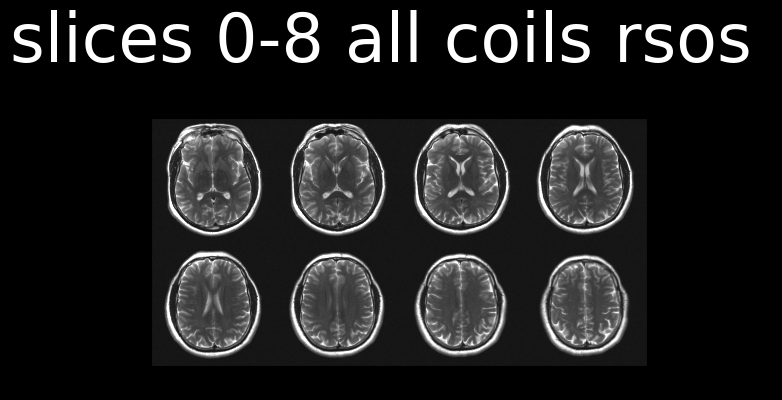

In [21]:
# mosaic function takes arguments : (img, num_row, num_col, fig_num, clim, title = '', use_transpose = False, use_flipud = False
mosaic(img_cropped_rsos[:,:,0:8], 2, 4, 1, [0,5e-4], 'slices 0-8 all coils rsos ', 0, 0)

# Save the current figure as a .png file
#plt.savefig('image_rsos_058.png', dpi=300, bbox_inches='tight')


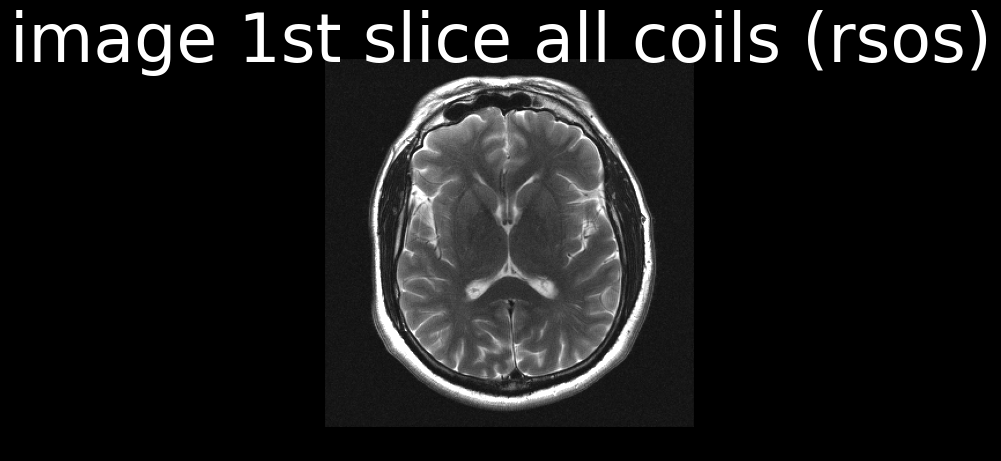

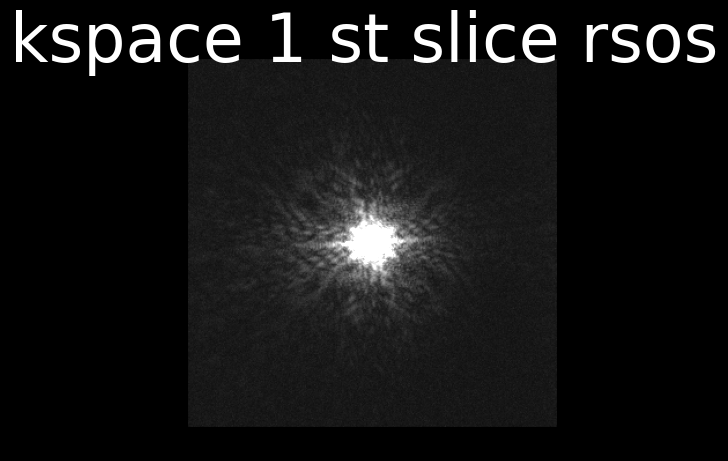

In [22]:
# %% select a slice from the cropped image

slice_index = 1  # Select the 1st slice (0-based index)
img_1st_slice = img_cropped[:,:,:,slice_index]

#Combining multi coil images into 1 single image
img_rsos = rsos(img_1st_slice, 2)

# Create kspace from image with 2-D discrete Fourier transform and then combine multi coil images into a single one
kspace_1st_slice = fft2call(img_1st_slice, 0, 1)
kspace_rsos = rsos(kspace_1st_slice, 2)

mosaic(img_rsos, 1, 1, 2, [0,5e-4], 'image 1st slice all coils (rsos)', 0, 0)
mosaic(kspace_rsos, 1, 1, 3, [0,5e-4], 'kspace 1 st slice rsos', 0, 0)

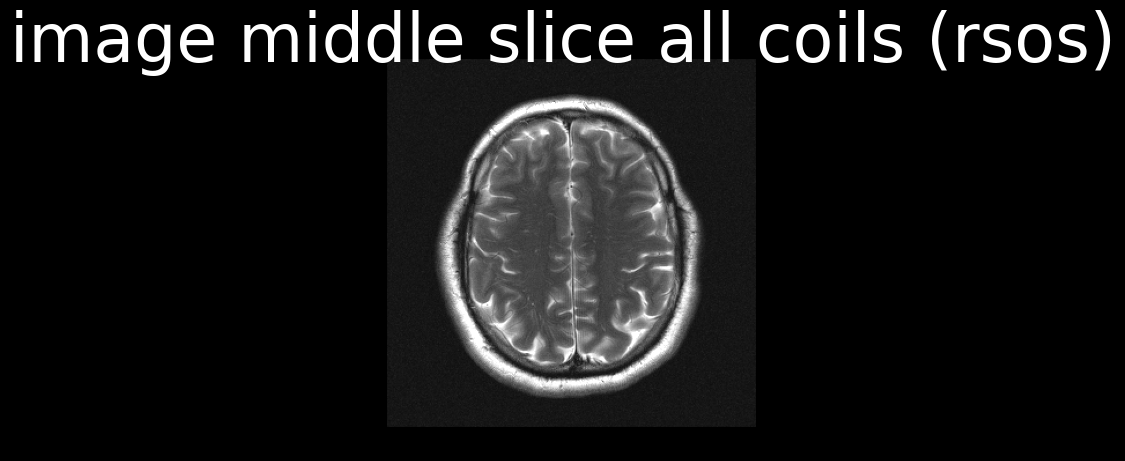

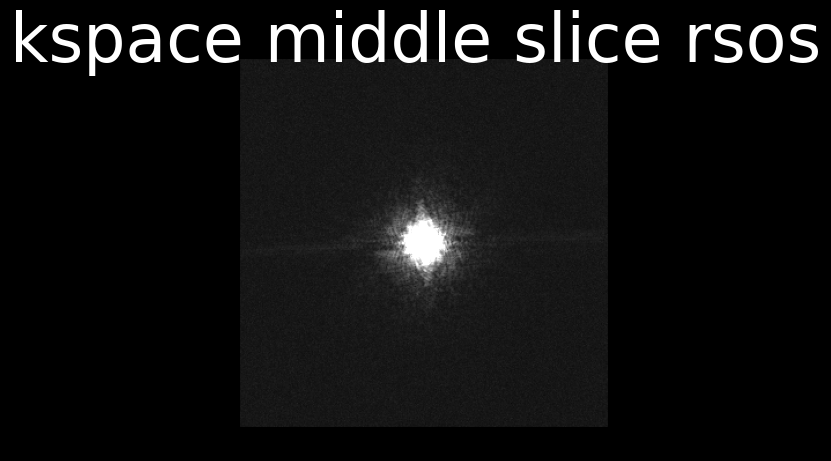

In [23]:
 # Choosing the middle slice of this volume
img_8st_slice = img_cropped[:,:,:,7]

#Combining multi coil images into 1 single image
img_middle_slice_rsos = rsos(img_8st_slice, 2)

# Create kspace from image with 2-D discrete Fourier transform and then combine multi coil images into a single one
kspace_8st_slice = fft2call(img_8st_slice, 0, 1)
kspace_8st_slice_rsos = rsos(kspace_8st_slice, 2)

mosaic(img_middle_slice_rsos, 1, 1, 2, [0,5e-4], 'image middle slice all coils (rsos)', 0, 0)
mosaic(kspace_8st_slice_rsos, 1, 1, 3, [0,5e-4], 'kspace middle slice rsos', 0, 0)

In [20]:
img_cropped_rsos.shape

(320, 320, 16)

In [21]:
img_cropped_rsos[:,0,0].min()

2.8052755093365095e-05

# Compute coil sensitivity maps using ESPIRiT
[Paper](https://pubmed.ncbi.nlm.nih.gov/23649942/) and 
[Library](https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.EspiritCalib.html#sigpy.mri.app.EspiritCalib) links

In [22]:
kspace_1st_slice.shape

(320, 320, 20)

In [23]:
# transpose so that coils are in the 0th dimension
kspace_1st_slice_calib = np.transpose(kspace_1st_slice, (2, 0, 1))
kspace_1st_slice_calib.shape

(20, 320, 320)

EspiritCalib:   0%|          | 0/100 [00:00<?, ?it/s]

Sensitivity maps shape: (20, 320, 320)


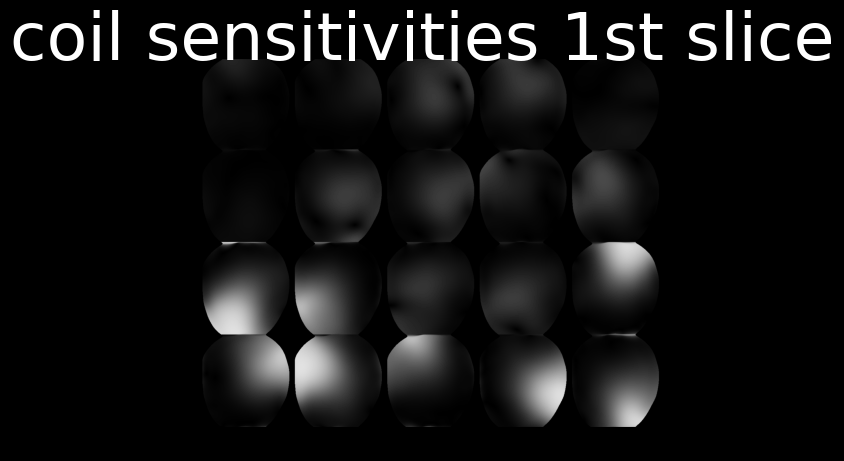

In [ ]:
calib_region = 24   # Calibration region size
crop_size = 0.8     # threshold for cropping the sensitivity maps
device = sp.Device(-1)  # Use CPU 

sensitivity_maps = app.EspiritCalib(kspace_1st_slice_calib, calib_width=calib_region, device=device, crop=crop_size).run()

print("Sensitivity maps shape:", sensitivity_maps.shape)  # [num_coils, height, width]

# switch coils back to the last dimension
sensitivity_maps = np.transpose(sensitivity_maps, (1, 2, 0))

# Display the sensitivity maps      
mosaic(np.abs(sensitivity_maps), 4, 5, 3, [0,1], 'coil sensitivities 1st slice', 0, 1)


EspiritCalib:   0%|          | 0/100 [00:00<?, ?it/s]

Sensitivity maps shape: (20, 320, 320)


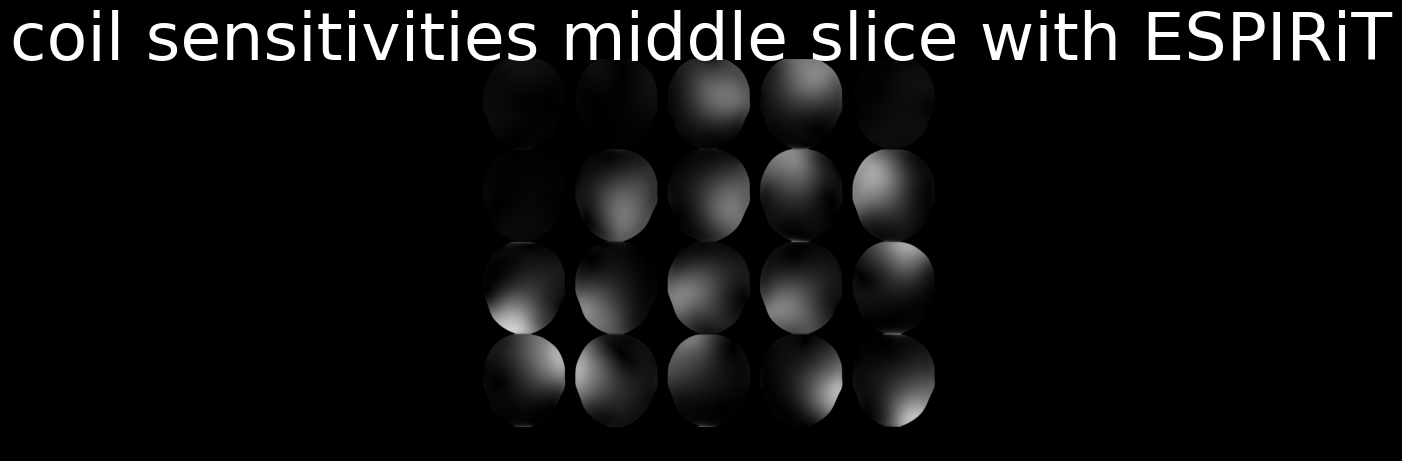

In [ ]:
# transpose so that coils are in the 0th dimension
kspace_8st_slice_calib = np.transpose(kspace_8st_slice, (2, 0, 1))
calib_region = 24   # Calibration region size
crop_size = 0.8     # threshold for cropping the sensitivity maps
device = sp.Device(-1)  # Use CPU 

sensitivity_maps_8st_slice = app.EspiritCalib(kspace_8st_slice_calib, calib_width=calib_region, device=device, crop=crop_size).run()

print("Sensitivity maps shape:", sensitivity_maps_8st_slice.shape)  # [num_coils, height, width]

# switch coils back to the last dimension
sensitivity_maps_8st_slice = np.transpose(sensitivity_maps_8st_slice, (1, 2, 0))

# Display the sensitivity maps      
mosaic(np.abs(sensitivity_maps_8st_slice), 4, 5, 3, [0,1], 'coil sensitivities middle slice with ESPIRiT', 0, 1)



# Creating Undersampled kspace

## create sampling pattern cartesian with variable density (center region presserved)
create a mask with values = 1 each 4 rows + in the center region of the image

In [26]:

sensitivity_maps_8st_slice.shape

(320, 320, 20)

In [27]:
sensitivity_maps_8st_slice[:,:,0].shape

(320, 320)

In [28]:

accel = 4   # acceleration factor
# Getting the shape of sensitivity maps from 1 coil and saving it as tuple
img_shape = sensitivity_maps_8st_slice[:,:,0].shape
type(img_shape)


tuple

In [29]:
img_shape

(320, 320)

In [30]:
# Creating a mask filled with 0 with shape of img_shape
msk = np.zeros(img_shape, dtype=float)  # Initialize with the correct shape
msk.shape

(320, 320)

In [31]:
unique, counts = np.unique(msk[0], return_counts=True)
print(unique, counts)

[0.] [320]


In [32]:
# Fill with 1 each accel element, here each 4 element
msk[:, 0::accel] = 1   
msk

array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]])

In [33]:
unique, counts = np.unique(msk[0], return_counts=True)
print(unique, counts)

[0. 1.] [240  80]


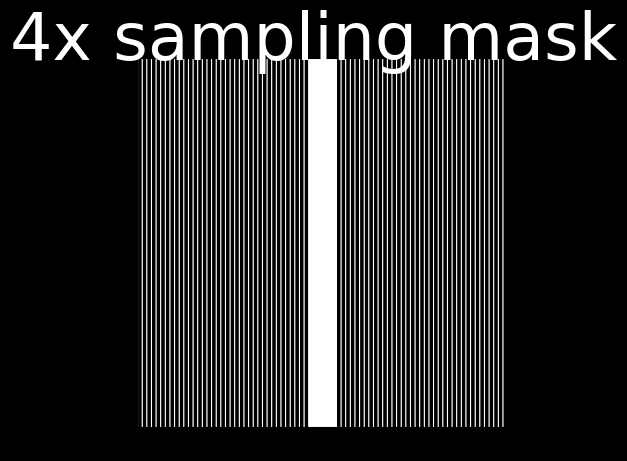

In [ ]:
# include the center of k-space
# calib_region = 24   # Calibration region size that was defined earlier
center_region = calib_region  # Size of the center region to keep
# modify the mask with 1 in the center region
msk[:, img_shape[1]//2 - center_region//2:img_shape[1]//2 + center_region//2] = 1

msk = msk[..., np.newaxis]  # Add dimensions to match kspace that is 3d array to have shape (320, 320, 1)

mosaic(msk[:,:,0], 1, 1, 4, [0,1], '4x sampling mask', 0, 1)

In [35]:
msk.shape

(320, 320, 1)

In [36]:
# np.prod Return the product of array elements over a given axis
np.prod(msk.shape)

102400

In [37]:
np.sum(msk)

31360.0

In [38]:
# real calculated acceleration factor calculated by dividing the value of the mask if all values are 1 by actual sum of values with 0 and 1
accl_factor = np.prod(msk.shape)/ np.sum(msk) 
print('actual acceleration factor: ', accl_factor)

actual acceleration factor:  3.2653061224489797


## Sense style coil combination: ground truth wih full sampled kspace

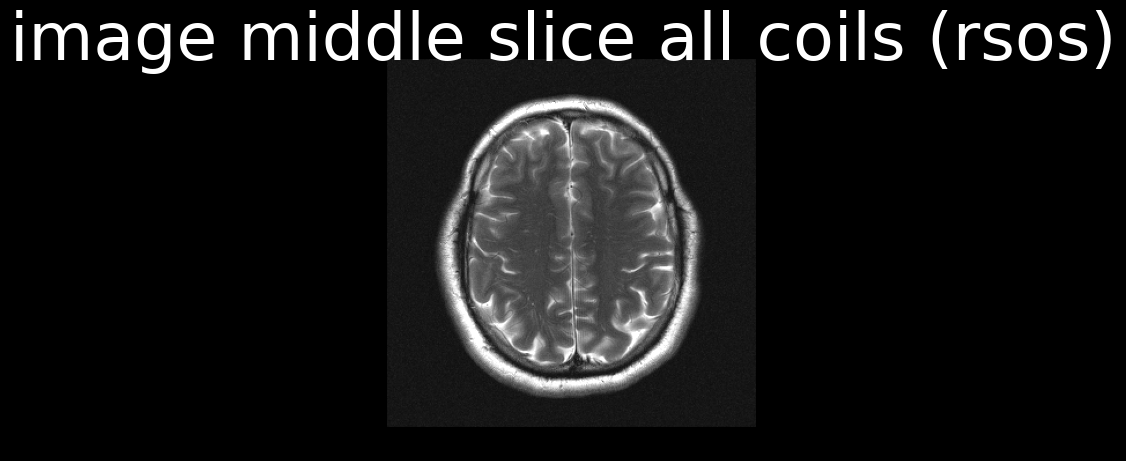

In [ ]:
mosaic(img_middle_slice_rsos, 1, 1, 2, [0,5e-4], 'image middle slice all coils (rsos)', 0, 0)

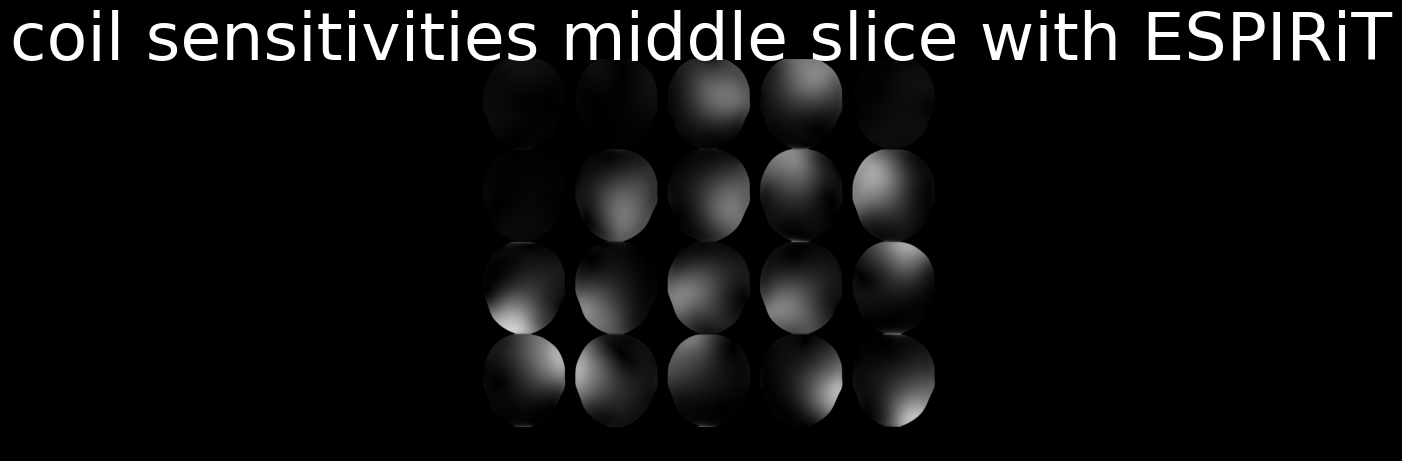

In [ ]:
# Display the sensitivity maps      
mosaic(np.abs(sensitivity_maps_8st_slice), 4, 5, 3, [0,1], 'coil sensitivities middle slice with ESPIRiT', 0, 1)

In [41]:
img_8st_slice.shape

(320, 320, 20)

Inputs: img_8st_slice and sensitivity_maps_8st_slice — both are complex arrays with shape (nx, ny, nCoils) (320,320,20).

[numpy.conj](https://numpy.org/doc/stable/reference/generated/numpy.conj.html) Return the complex conjugate, element-wise. The complex conjugate of a complex number is obtained by changing the sign of its imaginary part. <br>
Operation: np.conj(sensitivity_maps_8st_slice) takes the complex conjugate of the sensitivity maps. <br>

The * does element-wise multiplication between each coil image and that coil's conjugated sensitivity.

Sum: np.sum(..., 2) sums over axis 2 (the coil dimension), producing an array of shape (nx, ny).

Interpretation: This computes a SENSE-style coil combination (matched‑filter): for each pixel m(x,y) = sum_c img_c(x,y) * conj(s_c(x,y)). The result is a single complex image.

Why conjugate: Multiplying by the complex conjugate aligns coil phases and applies coil weighting so signals add constructively.

Note: This is a simple coil combination (matched-filter). A full SENSE reconstruction or optimal least-squares coil combine may include normalization by sum_c |s_c|^2 or explicit unfolding for under-sampled data.



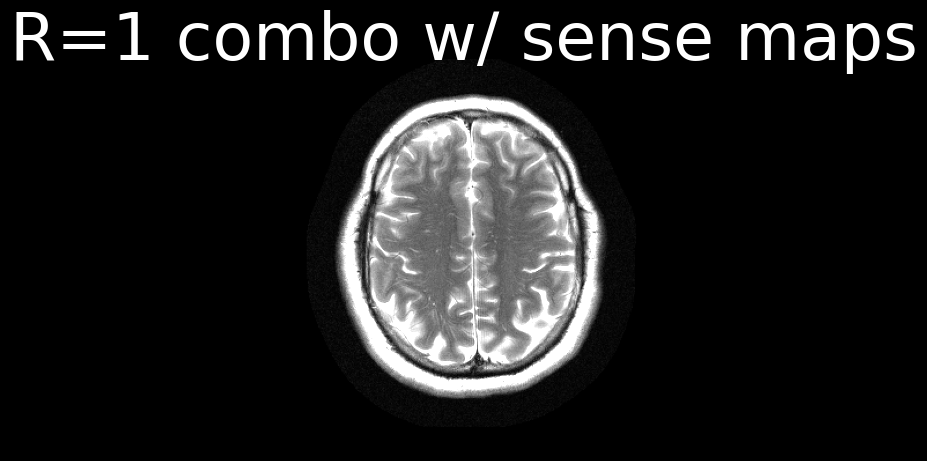

In [ ]:
# %% R=1 sense coil combination: ground truth
# https://numpy.org/doc/stable/reference/generated/numpy.conj.html

img_combo = np.sum(img_8st_slice * np.conj(sensitivity_maps_8st_slice),2)

mosaic(np.abs(img_combo), 2, 3, 2, [0,3e-4], 'R=1 combo w/ sense maps', 0, 1)

## 4X undersampled images with RSS coil combination on middle slice

In [43]:
# %% zero fill reconstruction
# create kspace 4 x undersampled and corresponding image and RSOS coil combination image of middle slice

kspace_accl = kspace_8st_slice * msk  # undersample k-space data with 0 values each 3 values and kept values 1 in 4 and the middle
kspace_accl.shape

(320, 320, 20)

In [44]:
kspace_accl[:,0,0].min()

(-2.165892013883517e-05-3.651015954323854e-06j)

In [ ]:
# inverse Fourier transform from kspace to image
img_zf = ifft2call(kspace_accl, 0, 1)
img_zf.shape

(320, 320, 20)

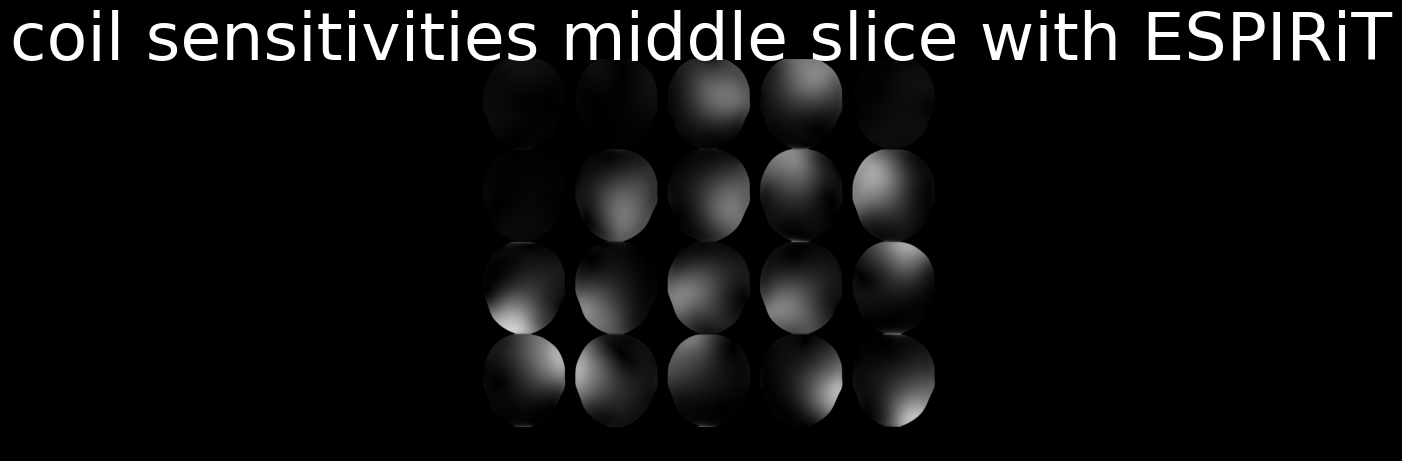

In [ ]:
mosaic(np.abs(sensitivity_maps_8st_slice), 4, 5, 3, [0,1], 'coil sensitivities middle slice with ESPIRiT', 0, 1)

/data_local/data_hdd/lehmansy/Reconstruction/tutorial/basic_sense_cs/LIBRARY.py:103: ComplexWarning: Casting complex values to real discards the imaginary part
  img_res[r*img.shape[0] : (r+1)*img.shape[0], c*img.shape[1] : (c+1)*img.shape[1]] = img[:,:,idx]


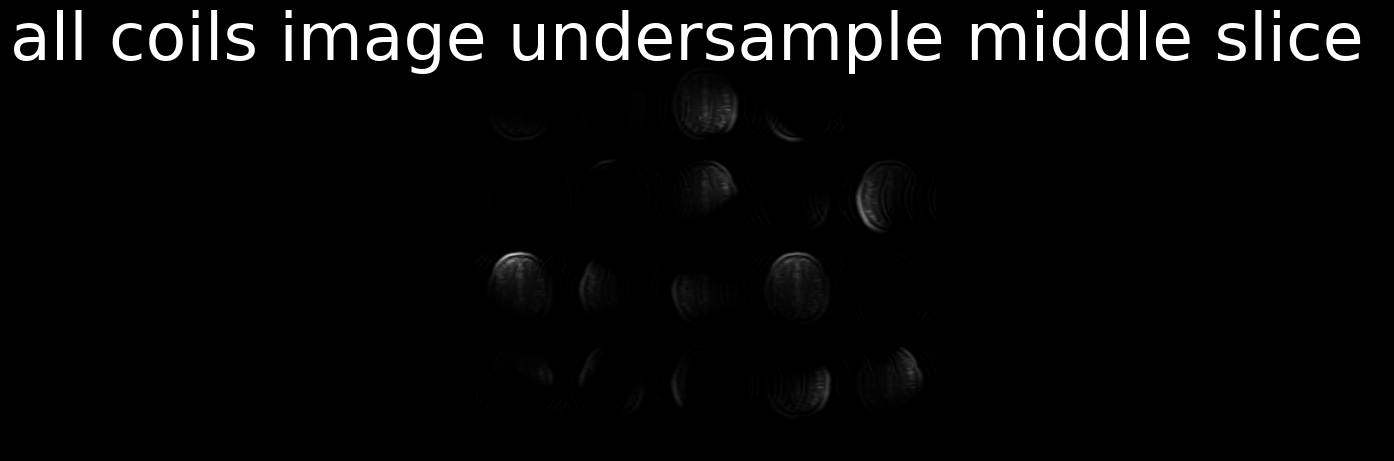

In [ ]:
# mosaic function takes arguments : (img, num_row, num_col, fig_num, clim, title = '', use_transpose = False, use_flipud = False
mosaic(img_zf[:,:,0:20], 4, 5, 3, [0,5e-4], 'all coils image undersample middle slice ', 0, 0)

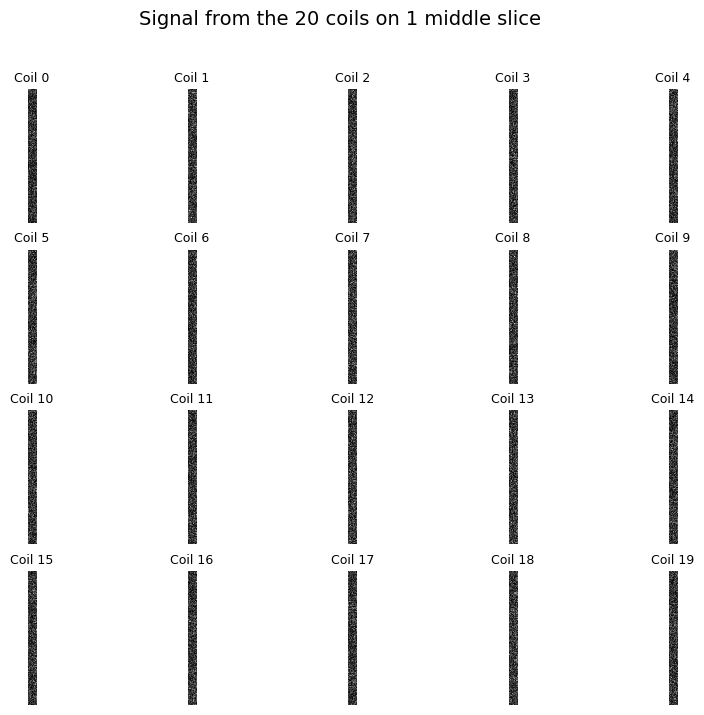

In [ ]:
show_coils_grid(np.abs(inverse_fft2_shift(kspace_accl)), coil_indices=[i for i in range(0, 20)], cmap='gray', nrows=4, ncols=5, fig_size=(10,8))

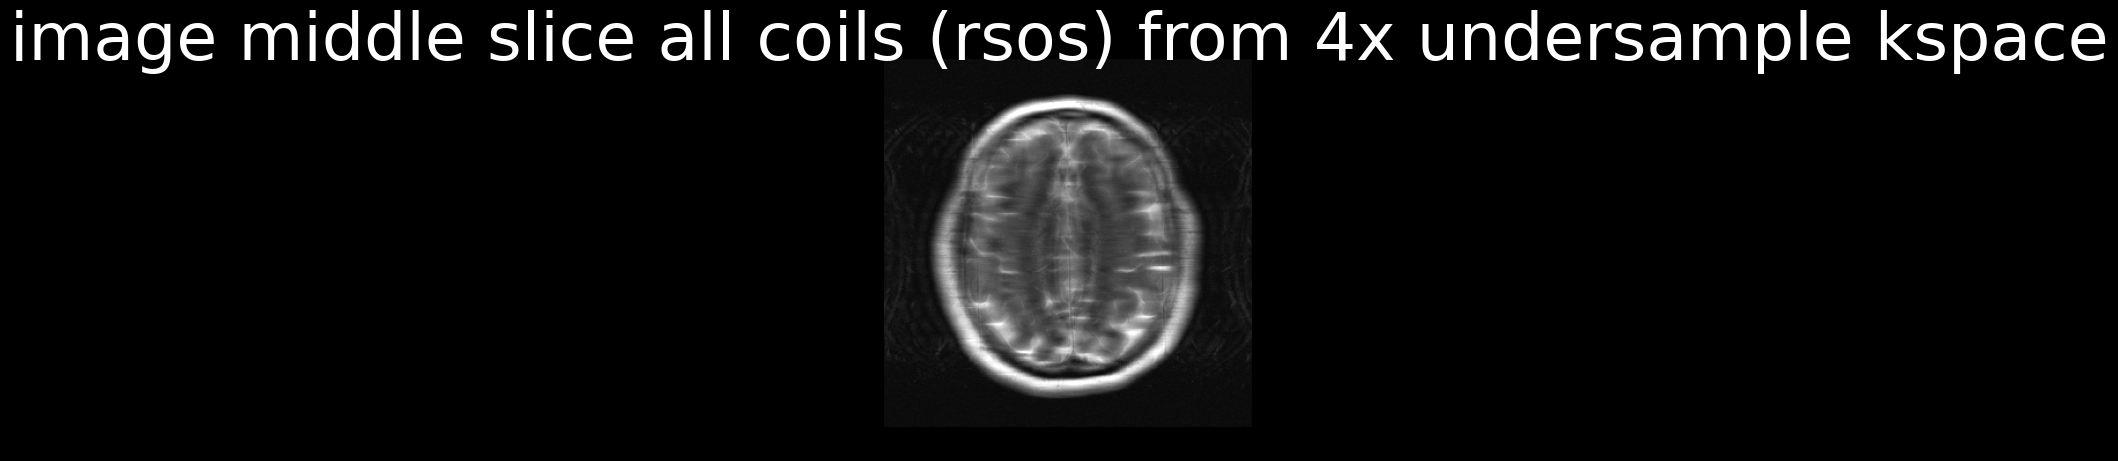

In [ ]:
img_zf_rsos = rsos(img_zf, 2)
mosaic(img_zf_rsos, 1, 1, 2, [0,5e-4], 'image middle slice all coils (rsos) from 4x undersample kspace', 0, 0)

## 4X undersampled images with SENSE style coil combination on middle slice

zero fill RMSE:  21.41488958818757  %


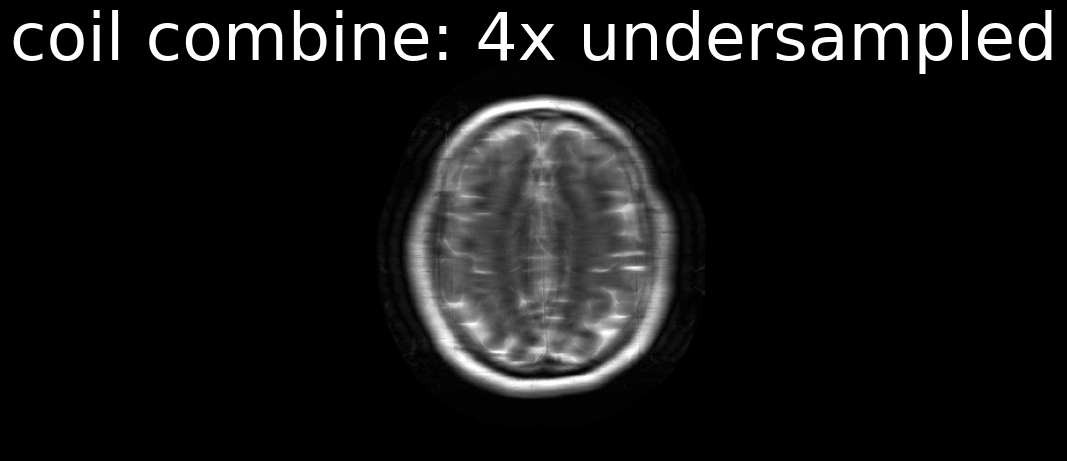

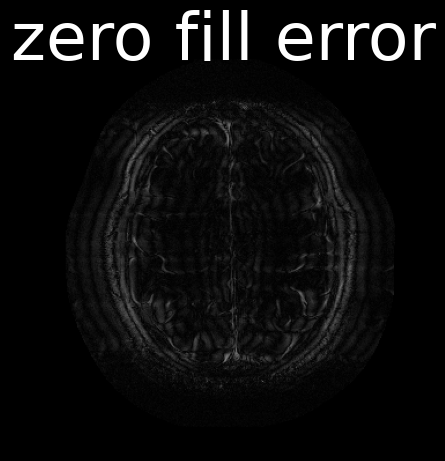

In [ ]:
# coil combine with estimated sensitivities
img_zf_combo = np.sum(img_zf * np.conj(sensitivity_maps_8st_slice), 2)

mosaic(np.abs(img_zf_combo), 1, 1, 1, [0,5e-4], 'coil combine: 4x undersampled', 0, 0)

# calculate the Root Mean Squared Error
rmse_zf = nrmse(img_zf_combo, img_combo)

print('zero fill RMSE: ', rmse_zf, ' %')

mosaic(np.abs(img_zf_combo - img_combo), 1, 1, 5, [0, 5e-4], 'zero fill error', 0, 0)

# Perform sense reconstruction with sigpy
[SenseRecon](https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.SenseRecon.html) from sigpy library. <br>
Takes as input sensitivity maps and undersampled kspace for 1 slice and output 1 reconstructed image with multi coil signal recombination

In [51]:
lambda_reg = 0

# Initialize a list to store the reconstructed images
sense_reconstructions = []

sens = np.transpose(sensitivity_maps_8st_slice, (2, 0, 1))  # Transpose so that coils are in the first dimension

# Transpose the k-space data to have coils in the first dimension
kspace_use = np.transpose(kspace_accl, (2, 0, 1))

# Perform SENSE reconstruction for the current echo
sense_recon = app.SenseRecon(
    y = kspace_use,  # Undersampled k-space data for the slice
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_reg,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # progress bar for each echo
)


# Run the reconstruction and store the result
img_sense = sense_recon.run()
sense_reconstructions.append(img_sense)
sense_reconstructions

SenseRecon:   0%|          | 0/100 [00:00<?, ?it/s]

[array([[0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
        ...,
        [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j]])]

In [52]:
# list of 20 lists. 1 for each coil
len(sense_reconstructions[0])

320

In [53]:
# Convert the list to a NumPy array for easier handling
sense_reconstructions = np.stack(sense_reconstructions, axis=2)
sense_reconstructions.shape

(320, 320, 1)

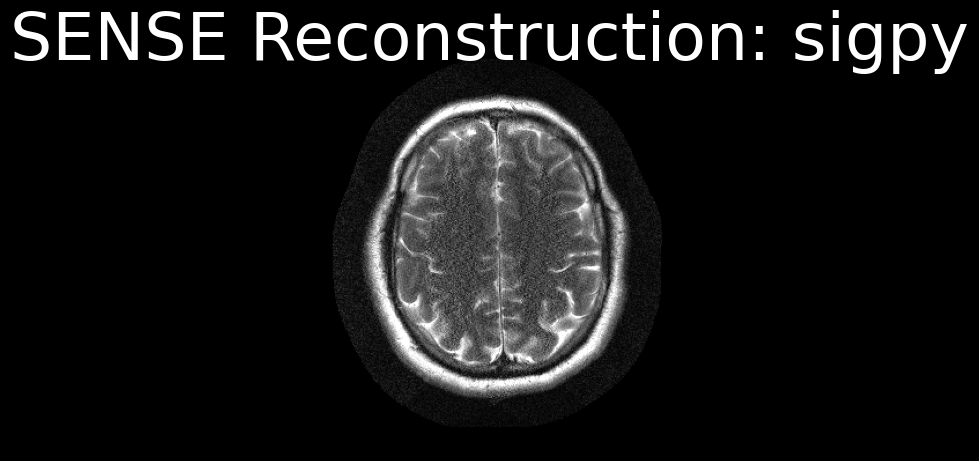

In [ ]:
# Display the reconstructed echoes
mosaic(np.abs(sense_reconstructions), 1, 1, 4, [0, 5e-4], 'SENSE Reconstruction: sigpy', 0, 0)

sigpy SENSE RMSE:  21.959577012511534  %


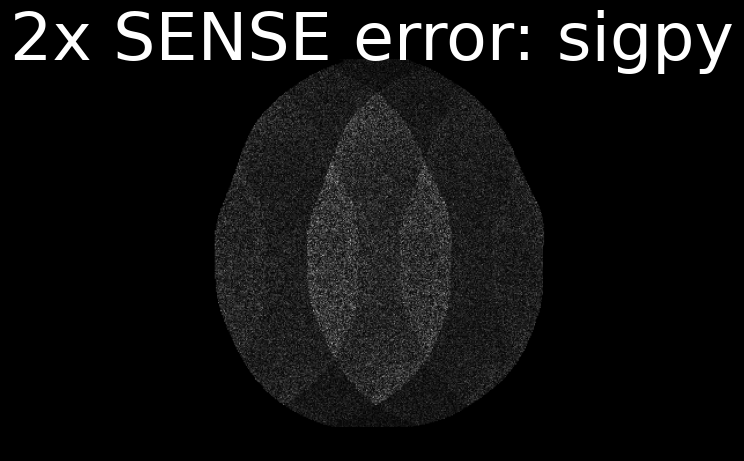

In [ ]:


# compute rmse from sigpy sense recon
rmse_sigpy = nrmse(sense_reconstructions[:,:,0], img_combo)

print('sigpy SENSE RMSE: ', rmse_sigpy, ' %')

mosaic(2*np.abs(sense_reconstructions[:,:,0] - img_combo), 1, 1, 4, [0, 5e-4], '2x SENSE error: sigpy', 0, 0   )


# Simple gradient descent sense reconstruction for comparison
Purpose: solve the linear least-squares SENSE problem (reconstruct a single image x from undersampled multi-coil k-space) by gradient descent on ||A x - y||_2^2, where A applies per-coil sensitivity maps, 2D FFT, and the sampling mask. 
Goal: find image x that makes the forward model A(x) match measured k-space y by minimizing least-squares error: minimize ||A(x) − y||_2^2.

Key variables:

num_iters, step_size: number of GD iterations and the step size (learning rate).
sensitivity_maps_8st_slice: sensitivity maps with shape (nx, ny, nCoils).
cs = np.conj(sensitivity_maps_8st_slice): complex conjugate of coil sensitivities (used in adjoint).
x = img_zf_combo[..., np.newaxis]: current image estimate, shaped (nx, ny, 1) to broadcast across coils.
msk: sampling mask (broadcastable to coil dimension).
kspace_accl: measured undersampled k-space (shape (nx, ny, nCoils)).
img_combo: ground-truth combined image for comparison.
Per-iteration operations (inside loop):

Forward model: compute predicted undersampled k-space for current x:
x * sensitivity_maps_8st_slice → per-coil images (broadcast to (nx,ny,nCoils)).
lib.fft2call(...,0,1) → per-coil k-space.
multiply by msk → apply undersampling.
residual: res = msk * fft2call(...) - kspace_accl = A x - y.
Adjoint (compute gradient): bring residual back to image domain and combine coils:
lib.ifft2call(res,0,1) → per-coil image-domain residuals.
multiply by cs (conj sensitivities) and sum over coils:
tmp = np.sum(cs * ifft2call(res), 2) gives A^H (A x - y) with shape (nx, ny).
Gradient step:
x = x - step_size * tmp[..., np.newaxis] updates the estimate (keeps coil axis).
After loop:

img_recon = x[:,:,0] extracts the reconstructed 2D image.
lib.nrmse(img_recon, img_combo) computes normalized RMSE (percentage) against the reference img_combo.
Interpretation / math (compact):

A(x) = msk * FFT2( x * s ), gradient = A^H(A x - y), update: x ← x − α A^H(A x − y).
Uses magnitudes for complex arithmetic where appropriate (conjugation aligns coil phases).
Caveats / notes:

This is an unregularized least-squares GD (no Tikhonov or sparsity terms).
Convergence and quality depend on step_size; too large can diverge.
lib.fft2call / lib.ifft2call include shifting/normalization—so A and A^H are implemented consistently here.


## Decomposition of the process that runs gradient descent and track NRMSE per iteration

In [63]:
num_iters_plot = 5
step_size_plot = 2 # learning rate
# Calculate the conjugate of coil sensitivity
cs = np.conj(sensitivity_maps_8st_slice)
cs.shape

(320, 320, 20)

In [57]:
# start from zero-filled combined image img_Zf is the image obtained by iTF of the undersampled kspace
# and img_zf_combo that is the combined undersampled image from the 20 coils  img_zf_combo = np.sum(img_zf * np.conj(sensitivity_maps), 2)
x_gd = img_zf_combo.copy()[..., np.newaxis]
x_gd.shape

(320, 320, 1)

In [58]:
test = x_gd * sensitivity_maps_8st_slice
test.shape

(320, 320, 20)

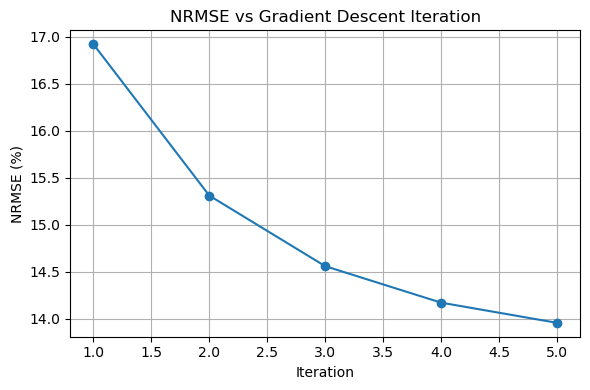

Final NRMSE:  13.956983742935252 %


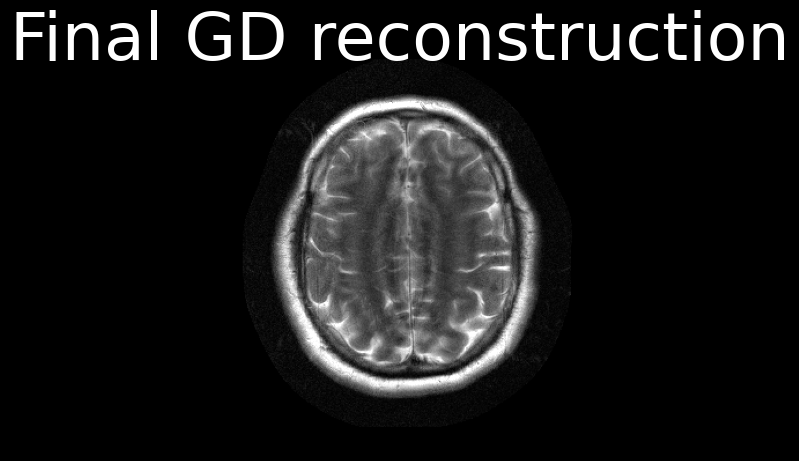

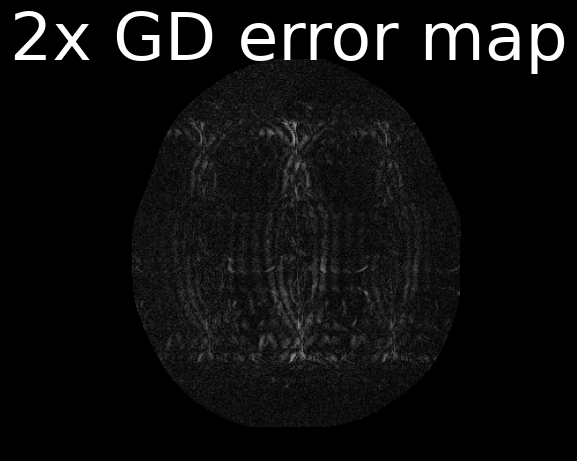

In [ ]:
# at each iteration

nrmse_list = []
for j in range(num_iters_plot):
    res = msk * fft2call(x_gd * sensitivity_maps_8st_slice, 0, 1) - kspace_accl
    tmp = np.sum(cs * ifft2call(res, 0, 1), 2)
    x_gd = x_gd - step_size_plot * tmp[..., np.newaxis]

    img_recon_gd = x_gd[:, :, 0]
    nrmse_val = nrmse(img_recon_gd, img_combo)
    nrmse_list.append(nrmse_val)

    if (j + 1) % 10 == 0:
        print(f"Iter {j+1}/{num_iters_plot} — NRMSE: {nrmse_val:.4f} %")

# Plot NRMSE vs iteration
plt.figure(figsize=(6,4))
plt.plot(np.arange(1, num_iters_plot+1), nrmse_list, '-o')
plt.xlabel('Iteration')
plt.ylabel('NRMSE (%)')
plt.title('NRMSE vs Gradient Descent Iteration')
plt.grid(True)
plt.tight_layout()
plt.show()

# Show final reconstruction and error map
mosaic(np.abs(img_recon_gd), 1, 1, 6, [0, 5e-4], 'Final GD reconstruction', 0, 0)
mosaic(2*np.abs(img_recon_gd - img_combo), 1, 1, 7, [0, 5e-4], '2x GD error map', 0, 0)

print('Final NRMSE: ', nrmse_list[-1], '%')

Completed iteration 10/100 
Completed iteration 20/100 
Completed iteration 30/100 
Completed iteration 40/100 
Completed iteration 50/100 
Completed iteration 60/100 
Completed iteration 70/100 
Completed iteration 80/100 
Completed iteration 90/100 
Completed iteration 100/100 
gradient descent RMSE:  20.782300419702512  %


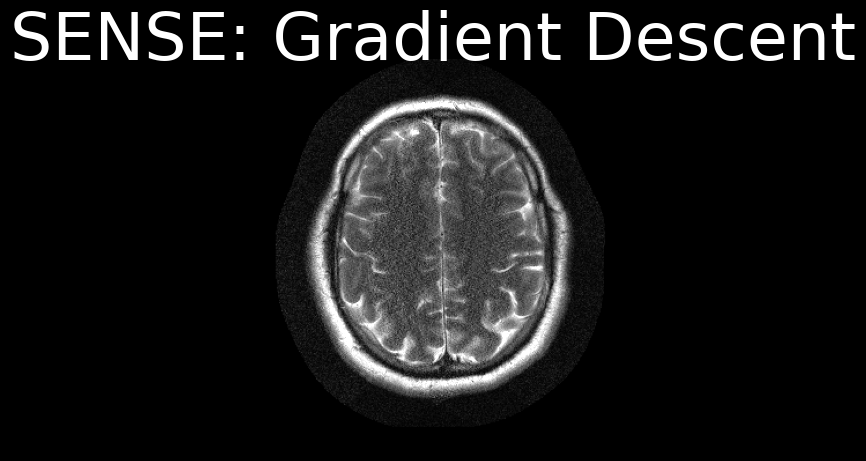

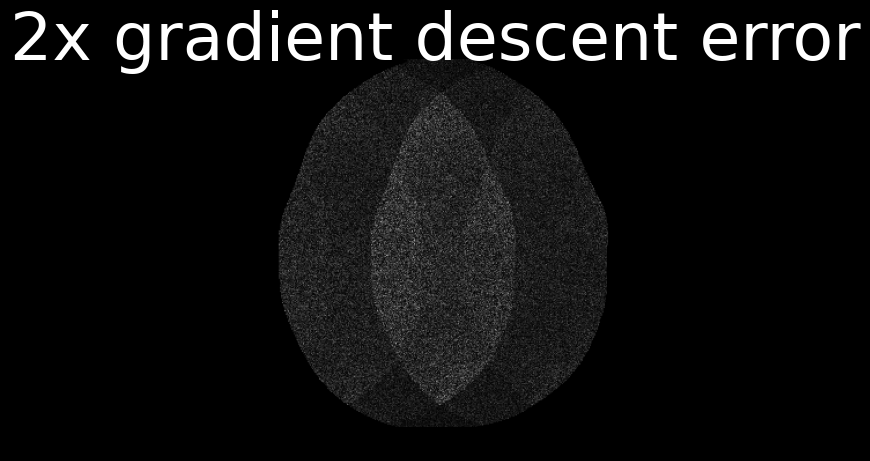

In [ ]:
num_iters = 100 # number of iterations for gradient descent
step_size = 2   # gradient descent step size 

cs = np.conj(sensitivity_maps_8st_slice)  # Conjugate of the sensitivity maps

x = img_zf_combo    # Initialize x with the zero-filled reconstruction
x = x[..., np.newaxis]

for j in range(num_iters):
    # Display iteration number every 10 iterations
    if (j + 1) % 10 == 0:
        print(f"Completed iteration {j + 1}/{num_iters} ")

    # Ax-b; mismatch
    res = msk * fft2call(x * sensitivity_maps_8st_slice, 0, 1) - kspace_accl

    # x = x - step_size * A'(Ax-b)
    tmp = np.sum(cs * ifft2call(res, 0, 1), 2)
    x = x - step_size * tmp[..., np.newaxis]

img_recon = x[:,:,0]

# Display the reconstructed image
mosaic(np.abs(img_recon), 1, 1, 4, [0, 5e-4], 'SENSE: Gradient Descent', 0, 0)

 
# compute nrmse for gradient descent
rmse_grad = nrmse(img_recon, img_combo)

print('gradient descent RMSE: ', rmse_grad, ' %')

mosaic(2*np.abs(img_recon - img_combo), 1, 1, 5, [0, 5e-4], '2x gradient descent error', 0, 0)

## Gradient descent and plot NRMSE at each iteration

Iter 10/50 — NRMSE: 13.7953 %
Iter 20/50 — NRMSE: 14.8700 %
Iter 30/50 — NRMSE: 16.2636 %
Iter 40/50 — NRMSE: 17.4702 %
Iter 50/50 — NRMSE: 18.4222 %


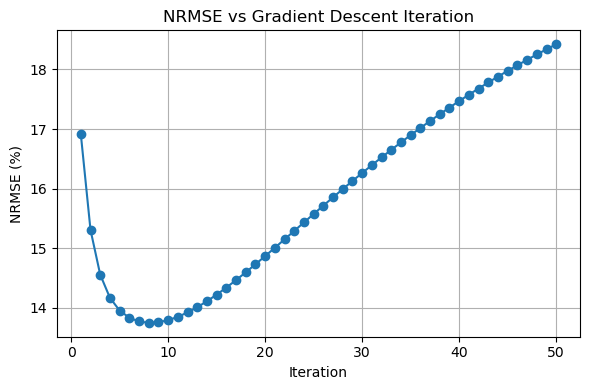

Final NRMSE:  18.422221440752757 %


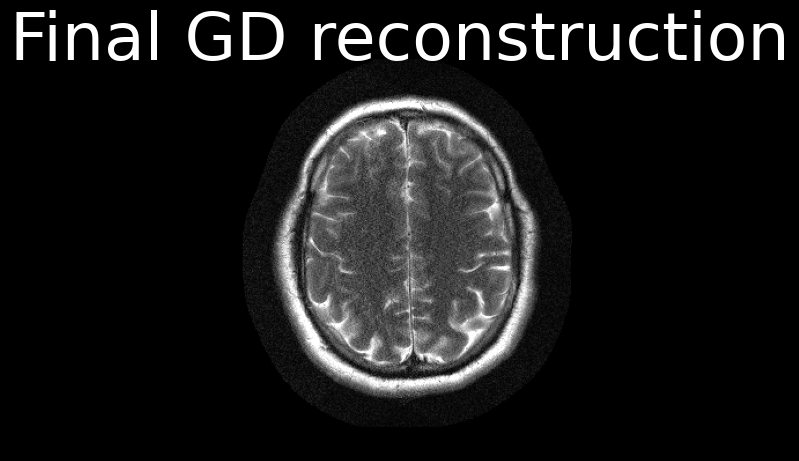

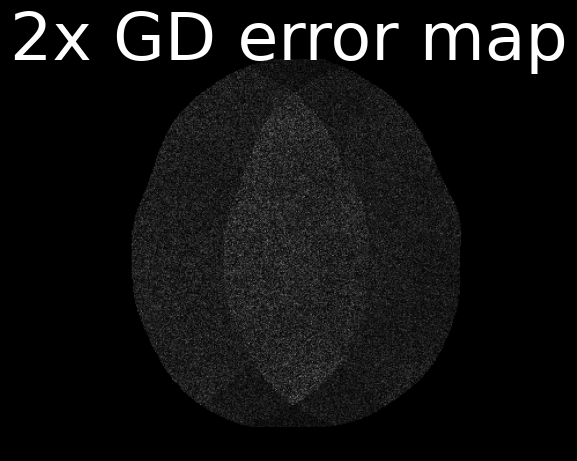

In [ ]:
# Run gradient descent and track NRMSE per iteration
# Adjust `num_iters` and `step_size` as needed before running.
num_iters_plot = 50
step_size_plot = 2

cs = np.conj(sensitivity_maps_8st_slice)
# start from zero-filled combined image
x_gd = img_zf_combo.copy()[..., np.newaxis]

nrmse_list = []

for j in range(num_iters_plot):
    res = msk * fft2call(x_gd * sensitivity_maps_8st_slice, 0, 1) - kspace_accl
    tmp = np.sum(cs * ifft2call(res, 0, 1), 2)
    x_gd = x_gd - step_size_plot * tmp[..., np.newaxis]

    img_recon_gd = x_gd[:, :, 0]
    nrmse_val = nrmse(img_recon_gd, img_combo)
    nrmse_list.append(nrmse_val)

    if (j + 1) % 10 == 0:
        print(f"Iter {j+1}/{num_iters_plot} — NRMSE: {nrmse_val:.4f} %")

# Plot NRMSE vs iteration
plt.figure(figsize=(6,4))
plt.plot(np.arange(1, num_iters_plot+1), nrmse_list, '-o')
plt.xlabel('Iteration')
plt.ylabel('NRMSE (%)')
plt.title('NRMSE vs Gradient Descent Iteration')
plt.grid(True)
plt.tight_layout()
plt.show()

# Show final reconstruction and error map
mosaic(np.abs(img_recon_gd), 1, 1, 6, [0, 5e-4], 'Final GD reconstruction', 0, 0)
mosaic(2*np.abs(img_recon_gd - img_combo), 1, 1, 7, [0, 5e-4], '2x GD error map', 0, 0)

print('Final NRMSE: ', nrmse_list[-1], '%')

MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

L1WaveletRecon:   0%|          | 0/100 [00:00<?, ?it/s]

sigpy wavelet RMSE:  9.236925333742889  %


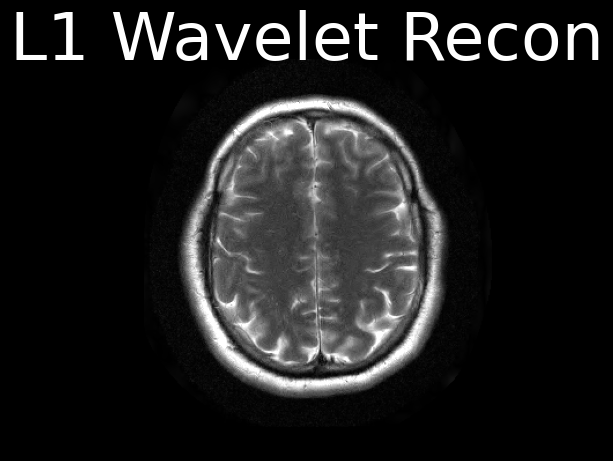

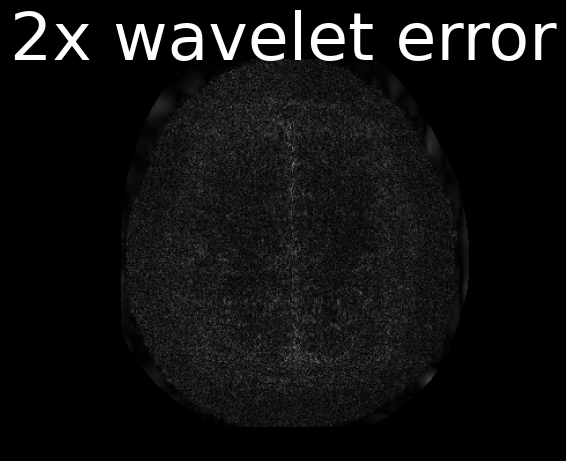

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_combo)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_combo), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


# Wavelet regularized reconstruction: sigpy 

## L1 wavelet regularization

MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

L1WaveletRecon:   0%|          | 0/100 [00:00<?, ?it/s]

sigpy wavelet RMSE:  9.236925333742889  %


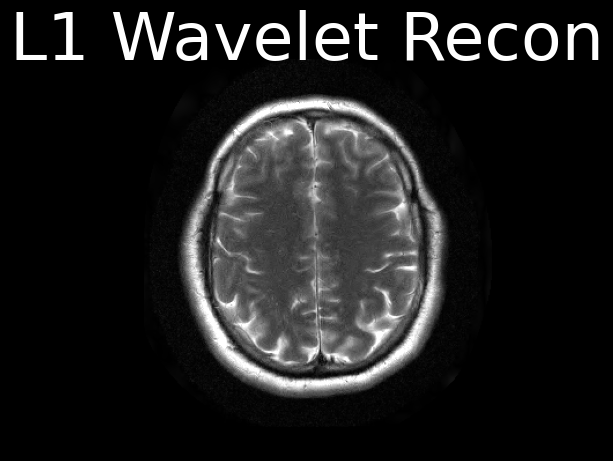

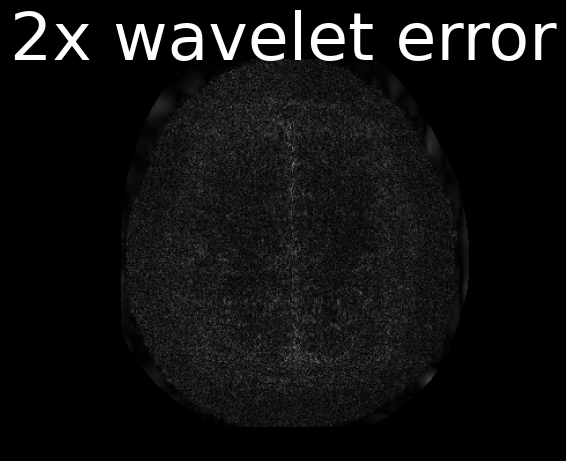

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_combo)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_combo), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

L1WaveletRecon:   0%|          | 0/100 [00:00<?, ?it/s]

sigpy wavelet RMSE:  9.236925333742889  %


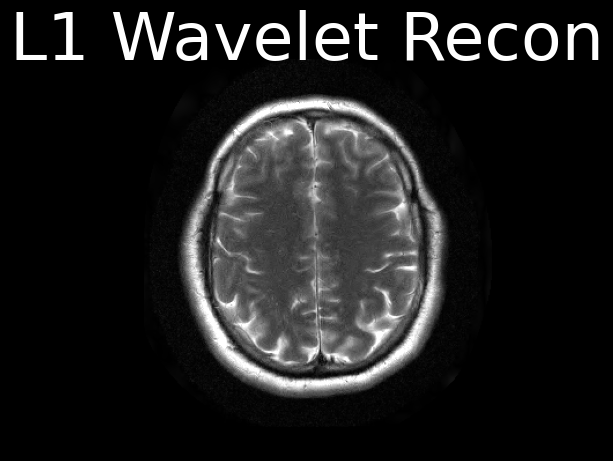

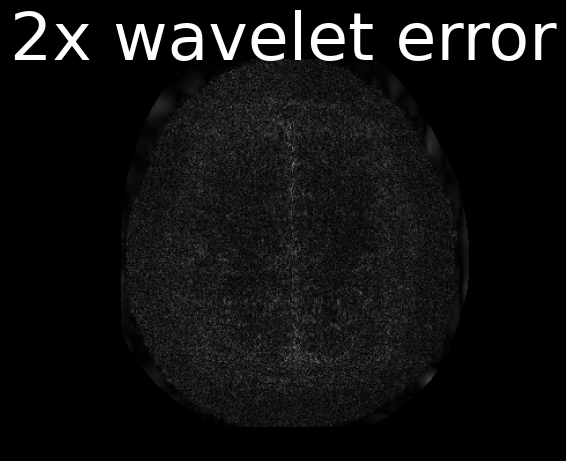

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_combo)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_combo), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

L1WaveletRecon:   0%|          | 0/100 [00:00<?, ?it/s]

sigpy wavelet RMSE:  9.236925333742889  %


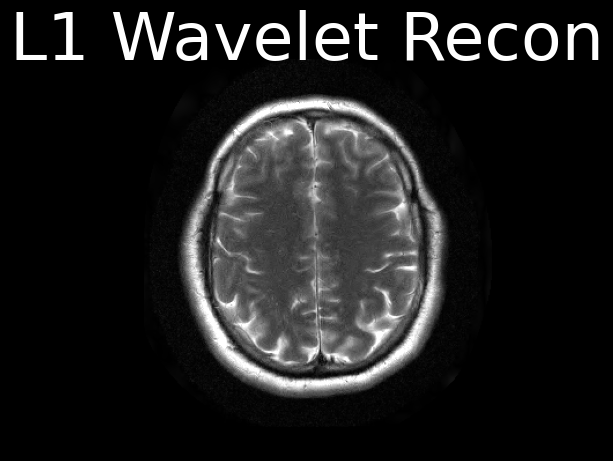

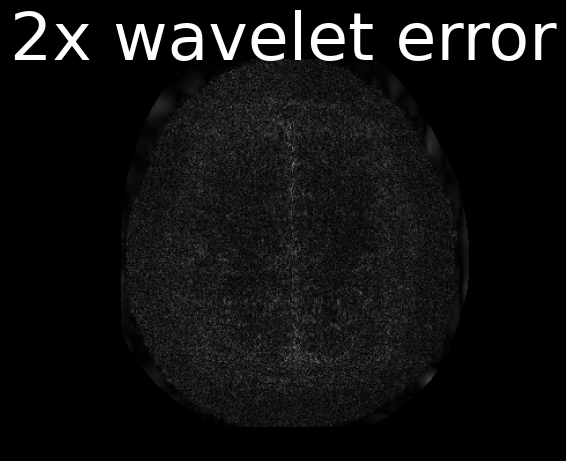

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_combo)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_combo), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


## Total variation regularized reconstruction 
https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.TotalVariationRecon.html#sigpy.mri.app.TotalVariationRecon

MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

TotalVariationRecon:   0%|          | 0/100 [00:00<?, ?it/s]

sigpy wavelet RMSE:  12.321470970374692  %


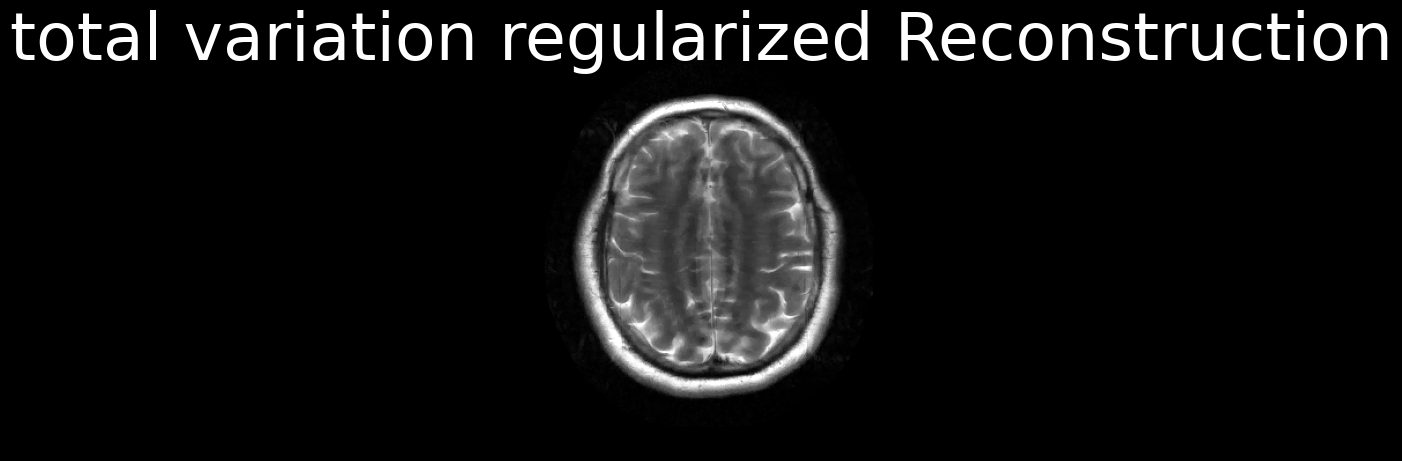

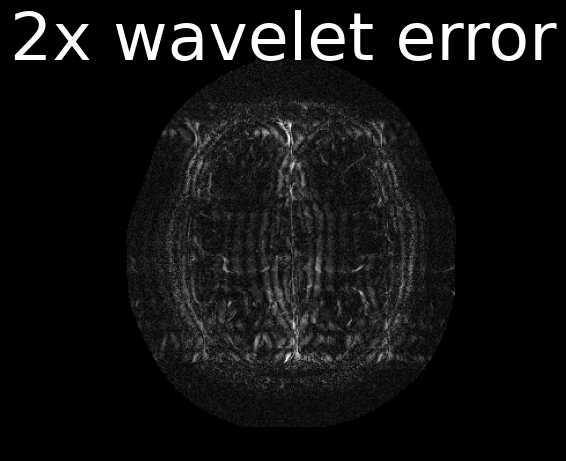

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter 
    
# Perform total variation regularized reconstruction
total_variation_recon = app.TotalVariationRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_total_variation = total_variation_recon.run()

non_zero_mask = np.abs(sensitivity_maps_8st_slice[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
total_variation_reconstructions = img_total_variation * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(total_variation_reconstructions), 1, 1, 4, [0, 5e-4], 'total variation regularized Reconstruction', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(total_variation_reconstructions, img_combo)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(total_variation_reconstructions - img_combo), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)
